In [7]:

# Standard library
import copy
import json
import os
import random
from itertools import product

# Data processing
import joblib
import networkx as nx
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt

# PyTorch
import torch
import torch.nn as nn
import torch.nn.functional as F

# PyTorch Geometric
from torch_geometric.data import Data
from torch_geometric.nn import GCNConv
from torch_geometric.transforms import RandomLinkSplit

# Classical machine learning models
from catboost import CatBoostClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    auc,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)


In [8]:
dataset = np.load("data/processed/link_prediction_dataset.npz")

X_train = dataset["X_train"]
X_val   = dataset["X_val"]
X_test  = dataset["X_test"]

y_train = dataset["y_train"]
y_val   = dataset["y_val"]
y_test  = dataset["y_test"]

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)


class Net(nn.Module):
    def __init__(
        self,
        in_channels,
        hidden_channels=32,
        out_channels=16,
        edge_feature_channels=26,
    ):
        super().__init__()

        self.conv1 = GCNConv(in_channels, hidden_channels)
        self.conv2 = GCNConv(hidden_channels, out_channels)

        decoder_input_channels = (
            3 * out_channels + edge_feature_channels
        )

        self.decoder = nn.Sequential(
            nn.Linear(decoder_input_channels, 64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 1),
        )

    def encode(self, x, edge_index):
        x = F.relu(self.conv1(x, edge_index))
        return self.conv2(x, edge_index)

    def decode(self, z, edge_label_index, edge_features):
        src = z[edge_label_index[0]]
        dst = z[edge_label_index[1]]

        edge_embedding = torch.cat(
            [
                src + dst,
                torch.abs(src - dst),
                src * dst,
                edge_features,
            ],
            dim=-1,
        )

        return self.decoder(edge_embedding).squeeze(-1)


device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# For trusted files you created yourself.
# weights_only=False may be needed for PyG Data objects
# on newer PyTorch versions.
saved = torch.load(
    "data/processed/link_prediction_graphs.pt",
    map_location="cpu",
    weights_only=False,
)

x = saved["x"].to(device)
train_data = saved["train_data"].to(device)
val_data = saved["val_data"].to(device)
test_data = saved["test_data"].to(device)

print("Node features:", x.shape)
print("Train graph:", train_data.edge_index.shape)
print("Validation candidates:", val_data.edge_label_index.shape)
print("Test candidates:", test_data.edge_label_index.shape)

Training: (1020, 26) (1020,)
Validation: (1274, 26) (1274,)
Test: (1274, 26) (1274,)
Node features: torch.Size([1800, 6])
Train graph: torch.Size([2, 9186])
Validation candidates: torch.Size([2, 1274])
Test candidates: torch.Size([2, 1274])


# Eval

Device: cpu
Validation: (1274, 26) (1274,)
Test: (1274, 26) (1274,)

Loading Logistic Regression...
Validation F1=0.7825 | Threshold=0.36

Loading Random Forest...
Validation F1=0.8142 | Threshold=0.44

Loading XGBoost...
Validation F1=0.8126 | Threshold=0.48

Loading CatBoost...
Validation F1=0.8144 | Threshold=0.41

Loading GNN...
Validation F1=0.7984 | Threshold=0.24

FINE-TUNED MODEL TEST RESULTS
              Model  Threshold  Validation F1  Accuracy  Balanced Accuracy  Precision  Recall  Specificity     F1  ROC-AUC  Average Precision  TP  FP  TN  FN
                GNN       0.24         0.7984    0.7724             0.7724     0.7182  0.8964       0.6484 0.7975   0.8762             0.8756 571 224 413  66
           CatBoost       0.41         0.8144    0.7677             0.7677     0.7047  0.9215       0.6138 0.7986   0.8734             0.8741 587 246 391  50
      Random Forest       0.44         0.8142    0.7786             0.7786     0.7141  0.9294       0.6279 0.8076   0.8760

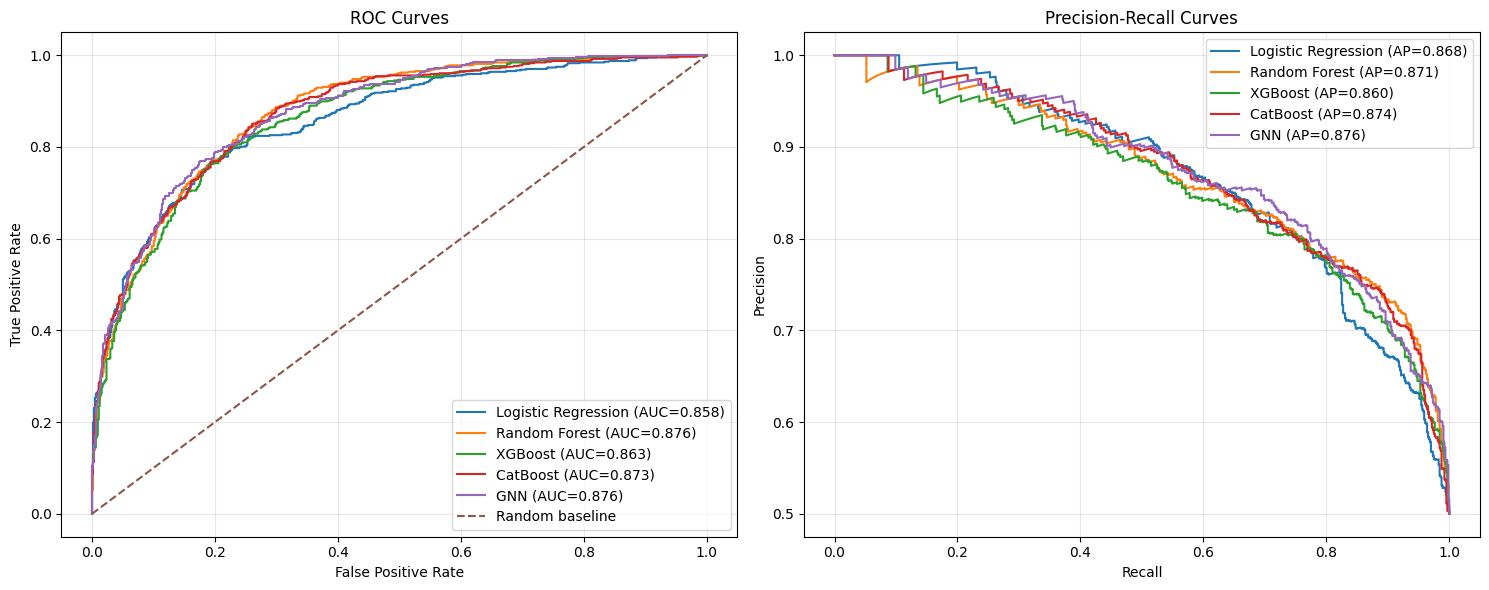

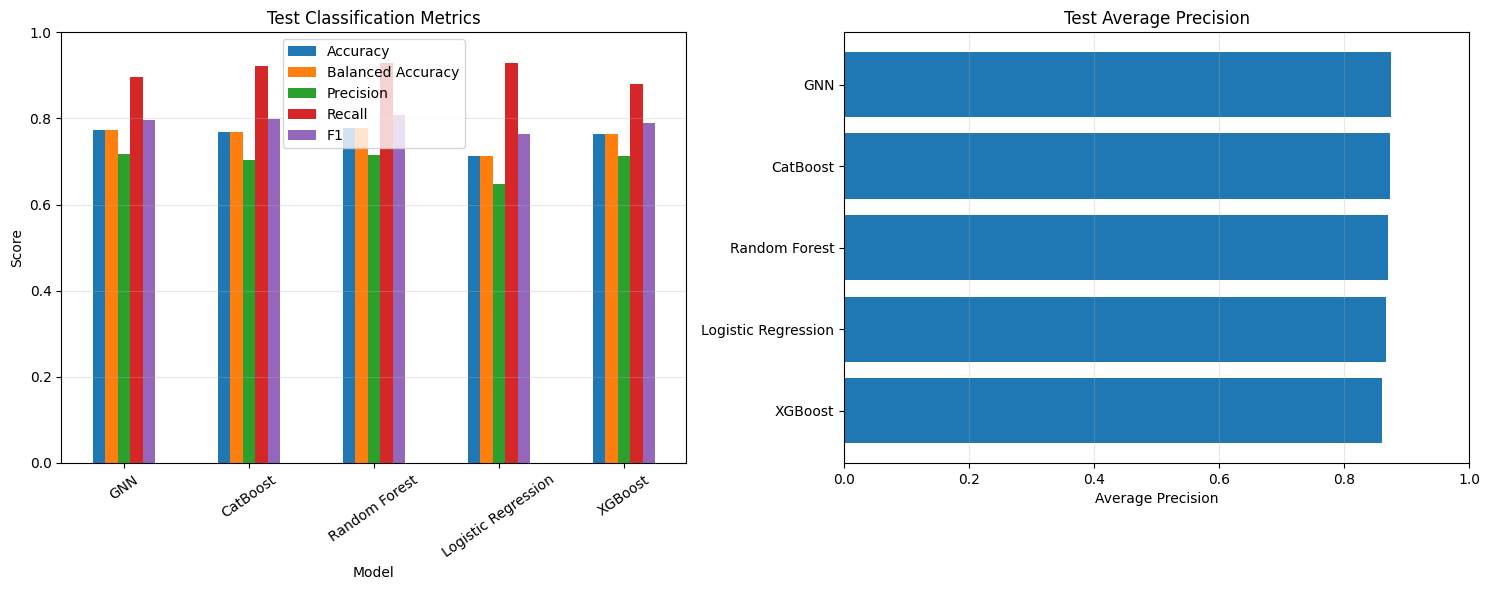

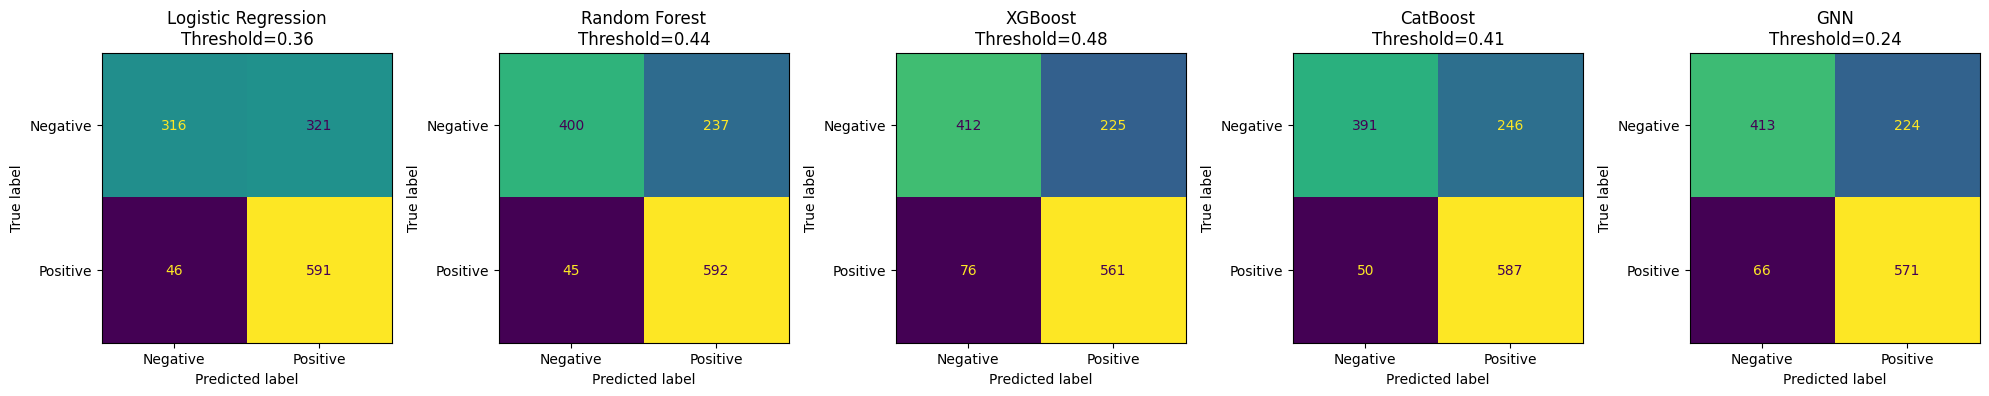


Results saved to: C:\Users\SemKj\Downloads\network_prediction\finetuned_model_evaluation
Available variables:
  results_df   - test metrics for loaded models
  predictions  - test probabilities, labels, and thresholds
  loaded_models - loaded fine-tuned model objects


In [ ]:

# ==========================================
# 1. CONFIGURATION
# ==========================================

from pathlib import Path
import copy
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

from torch_geometric.nn import GCNConv

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    precision_recall_curve,
)

DATASET_PATH = Path("data/processed/link_prediction_dataset.npz")
GRAPH_PATH = Path("data/processed/link_prediction_graphs.pt")
OUTPUT_DIR = Path("finetuning/finetuned_model_evaluation")

MODEL_PATHS = {
    "Logistic Regression": Path(
        r"finetuning\logistic_regression_accuracy_grid_results\best_logistic_regression.joblib"
    ),
    "Random Forest": Path(
        r"finetuning\randomforest_accuracy_grid_results\best_random_forest.joblib"
    ),
    "XGBoost": Path(
        r"finetuning\xgboost_accuracy_grid_results\best_xgboost.joblib"
    ),
    "CatBoost": Path(
        r"finetuning\catboost_accuracy_grid_results\best_catboost.cbm"
    ),
    # The GNN tuning script saves a PyTorch checkpoint, not joblib.
    "GNN": Path(
        r"finetuning\gnn_accuracy_grid_results\best_gnn.pt"
    ),
}

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)


# ==========================================
# 2. LOAD DATA
# ==========================================

dataset = np.load(DATASET_PATH)

X_val = dataset["X_val"]
X_test = dataset["X_test"]
y_val = dataset["y_val"].astype(int)
y_test = dataset["y_test"].astype(int)

# Load the graph splits for GNN inference.
saved_graphs = torch.load(
    GRAPH_PATH,
    map_location="cpu",
    weights_only=False,
)

x = saved_graphs["x"].to(device)
val_data = saved_graphs["val_data"].to(device)
test_data = saved_graphs["test_data"].to(device)

val_edge_features = torch.as_tensor(
    X_val, dtype=torch.float32, device=device
)
test_edge_features = torch.as_tensor(
    X_test, dtype=torch.float32, device=device
)

# Check that labels and candidate-edge features are aligned.
assert len(X_val) == len(y_val)
assert len(X_test) == len(y_test)
assert X_val.shape[1] == X_test.shape[1]

assert val_data.edge_label_index.shape[1] == len(X_val), (
    "Validation graph candidates and X_val have different lengths."
)
assert test_data.edge_label_index.shape[1] == len(X_test), (
    "Test graph candidates and X_test have different lengths."
)

print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)


# ==========================================
# 3. THRESHOLD SELECTION
# ==========================================

def find_best_f1_threshold(y_true, probabilities):
    """Select the threshold maximizing F1 on validation data."""
    y_true = np.asarray(y_true).astype(int)
    probabilities = np.asarray(probabilities, dtype=float)

    if len(y_true) != len(probabilities):
        raise ValueError("Labels and probabilities must have equal lengths.")

    if not np.isfinite(probabilities).all():
        raise ValueError("Probabilities contain NaN or infinite values.")

    thresholds = np.arange(0.05, 0.951, 0.01)

    scores = [
        f1_score(
            y_true,
            (probabilities >= threshold).astype(int),
            zero_division=0,
        )
        for threshold in thresholds
    ]

    best_score = max(scores)

    # If tied, prefer the threshold closest to 0.5.
    tied_indices = [
        i for i, score in enumerate(scores)
        if np.isclose(score, best_score)
    ]
    best_idx = min(
        tied_indices,
        key=lambda i: abs(thresholds[i] - 0.5),
    )

    return float(thresholds[best_idx]), float(scores[best_idx])


# ==========================================
# 4. GNN ARCHITECTURE
# Must match the architecture used during tuning.
# ==========================================

class Net(nn.Module):
    def __init__(
        self,
        in_channels,
        hidden_channels=32,
        out_channels=16,
        edge_feature_channels=26,
        dropout=0.2,
    ):
        super().__init__()

        self.conv1 = GCNConv(in_channels, hidden_channels)
        self.conv2 = GCNConv(hidden_channels, out_channels)
        self.dropout = dropout

        decoder_input_channels = (
            3 * out_channels + edge_feature_channels
        )

        self.decoder = nn.Sequential(
            nn.Linear(decoder_input_channels, 64),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(32, 1),
        )

    def encode(self, x, edge_index):
        z = F.relu(self.conv1(x, edge_index))
        z = F.dropout(z, p=self.dropout, training=self.training)
        return self.conv2(z, edge_index)

    def decode(self, z, edge_label_index, edge_features):
        src = z[edge_label_index[0]]
        dst = z[edge_label_index[1]]

        edge_embedding = torch.cat(
            [
                src + dst,
                torch.abs(src - dst),
                src * dst,
                edge_features,
            ],
            dim=-1,
        )

        return self.decoder(edge_embedding).squeeze(-1)



def load_gnn(checkpoint_path):
    """Load a fine-tuned GNN checkpoint without retraining."""
    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=False,
    )

    saved_params = checkpoint["model_params"]

    # Keep only parameters accepted by Net.__init__().
    architecture_params = {
        key: saved_params[key]
        for key in (
            "hidden_channels",
            "out_channels",
            "dropout",
        )
        if key in saved_params
    }

    model = Net(
        in_channels=checkpoint.get(
            "input_channels", x.shape[1]
        ),
        edge_feature_channels=checkpoint.get(
            "edge_feature_channels", X_val.shape[1]
        ),
        **architecture_params,
    ).to(device)

    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()

    return model



def gnn_probabilities(model, graph_data, edge_features):
    """Predict link probabilities for one saved graph split."""
    model.eval()

    with torch.no_grad():
        z = model.encode(
            graph_data.x,
            graph_data.edge_index,
        )

        logits = model.decode(
            z,
            graph_data.edge_label_index,
            edge_features,
        )

        probabilities = torch.sigmoid(logits).cpu().numpy()

    return probabilities


# ==========================================
# 5. LOAD MODELS AND SELECT THRESHOLDS
# ==========================================

predictions = {}
loaded_models = {}
threshold_rows = []

for name, model_path in MODEL_PATHS.items():
    if not model_path.is_file():
        print(f"\nSkipping {name}: file not found: {model_path}")
        continue

    print(f"\nLoading {name}...")

    if name == "GNN":
        model = load_gnn(model_path)

        val_probs = gnn_probabilities(
            model, val_data, val_edge_features
        )
        test_probs = gnn_probabilities(
            model, test_data, test_edge_features
        )

        loaded_models[name] = model

   
    else:
        if name == "CatBoost":
            model = CatBoostClassifier()
            model.load_model(str(model_path))
        else:
            model = joblib.load(model_path)

        val_probs = model.predict_proba(X_val)[:, 1]
        test_probs = model.predict_proba(X_test)[:, 1]

        loaded_models[name] = model


    # Select threshold exclusively using validation labels.
    threshold, validation_f1 = find_best_f1_threshold(
        y_val, val_probs
    )

    test_pred = (test_probs >= threshold).astype(int)

    predictions[name] = {
        "y_true": y_test.copy(),
        "y_probs": test_probs,
        "y_pred": test_pred,
        "threshold": threshold,
        "validation_f1": validation_f1,
    }

    threshold_rows.append({
        "Model": name,
        "Validation F1": validation_f1,
        "Threshold": threshold,
    })

    print(
        f"Validation F1={validation_f1:.4f} | "
        f"Threshold={threshold:.2f}"
    )

if not predictions:
    raise RuntimeError(
        "No models were loaded. Check MODEL_PATHS and the working directory."
    )


# ==========================================
# 6. TEST METRICS
# ==========================================

rows = []

for name, result in predictions.items():
    yt = result["y_true"]
    yp = result["y_pred"]
    probs = result["y_probs"]

    tn, fp, fn, tp = confusion_matrix(
        yt, yp, labels=[0, 1]
    ).ravel()

    rows.append({
        "Model": name,
        "Threshold": result["threshold"],
        "Validation F1": result["validation_f1"],
        "Accuracy": accuracy_score(yt, yp),
        "Balanced Accuracy": balanced_accuracy_score(yt, yp),
        "Precision": precision_score(yt, yp, zero_division=0),
        "Recall": recall_score(yt, yp, zero_division=0),
        "Specificity": tn / (tn + fp) if (tn + fp) else 0.0,
        "F1": f1_score(yt, yp, zero_division=0),
        "ROC-AUC": roc_auc_score(yt, probs),
        "Average Precision": average_precision_score(yt, probs),
        "TP": tp,
        "FP": fp,
        "TN": tn,
        "FN": fn,
    })

results_df = (
    pd.DataFrame(rows)
    .sort_values("Average Precision", ascending=False)
    .reset_index(drop=True)
)

print("\n" + "=" * 110)
print("FINE-TUNED MODEL TEST RESULTS")
print("=" * 110)

display_df = results_df.copy()

score_columns = [
    "Validation F1",
    "Accuracy",
    "Balanced Accuracy",
    "Precision",
    "Recall",
    "Specificity",
    "F1",
    "ROC-AUC",
    "Average Precision",
]

display_df[score_columns] = display_df[score_columns].round(4)
display_df["Threshold"] = display_df["Threshold"].round(2)

print(display_df.to_string(index=False))

results_df.to_csv(
    OUTPUT_DIR / "test_metrics.csv",
    index=False,
)

pd.DataFrame(threshold_rows).to_csv(
    OUTPUT_DIR / "validation_thresholds.csv",
    index=False,
)


# ==========================================
# 7. ROC AND PRECISION-RECALL CURVES
# ==========================================

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# ROC curves
ax = axes[0]

for name, result in predictions.items():
    fpr, tpr, _ = roc_curve(
        result["y_true"], result["y_probs"]
    )
    roc_auc = roc_auc_score(
        result["y_true"], result["y_probs"]
    )

    ax.plot(fpr, tpr, label=f"{name} (AUC={roc_auc:.3f})")

ax.plot([0, 1], [0, 1], "--", label="Random baseline")
ax.set_title("ROC Curves")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.legend()
ax.grid(True, alpha=0.3)

# Precision-recall curves
ax = axes[1]

for name, result in predictions.items():
    precision, recall, _ = precision_recall_curve(
        result["y_true"], result["y_probs"]
    )
    ap = average_precision_score(
        result["y_true"], result["y_probs"]
    )

    ax.plot(recall, precision, label=f"{name} (AP={ap:.3f})")

ax.set_title("Precision-Recall Curves")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "roc_pr_curves.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()


# ==========================================
# 8. METRIC COMPARISON
# ==========================================

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

results_df.set_index("Model")[
    ["Accuracy", "Balanced Accuracy", "Precision", "Recall", "F1"]
].plot(kind="bar", ax=axes[0])

axes[0].set_title("Test Classification Metrics")
axes[0].set_ylabel("Score")
axes[0].set_ylim(0, 1)
axes[0].tick_params(axis="x", rotation=35)
axes[0].grid(axis="y", alpha=0.3)

ap_sorted = results_df.sort_values("Average Precision")

axes[1].barh(
    ap_sorted["Model"],
    ap_sorted["Average Precision"],
)
axes[1].set_title("Test Average Precision")
axes[1].set_xlabel("Average Precision")
axes[1].set_xlim(0, 1)
axes[1].grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "metric_comparison.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()


# ==========================================
# 9. CONFUSION MATRICES
# ==========================================

n_models = len(predictions)

fig, axes = plt.subplots(
    1,
    n_models,
    figsize=(4 * n_models, 4),
    squeeze=False,
)

for ax, (name, result) in zip(axes.ravel(), predictions.items()):
    cm = confusion_matrix(
        result["y_true"],
        result["y_pred"],
        labels=[0, 1],
    )

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Negative", "Positive"],
    ).plot(
        ax=ax,
        values_format="d",
        colorbar=False,
    )

    ax.set_title(
        f"{name}\nThreshold={result['threshold']:.2f}"
    )

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "confusion_matrices.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()


# ==========================================
# 10. OUTPUTS
# ==========================================

print(f"\nResults saved to: {OUTPUT_DIR.resolve()}")
print("Available variables:")
print("  results_df   - test metrics for loaded models")
print("  predictions  - test probabilities, labels, and thresholds")
print("  loaded_models - loaded fine-tuned model objects")
